In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load DataSet

In [10]:
df = pd.read_csv("c:\\Users\\cheta\\Downloads\\advertising_sales (1).csv")
df.head()

,TV,Radio,Newspaper,Sales
0,192.1,1.3,31.6,12.4
1,203.2,44.6,10.2,23.3
2,127.0,1.5,25.2,8.7
3,60.2,32.5,62.3,11.8
4,66.7,29.5,92.3,14.5


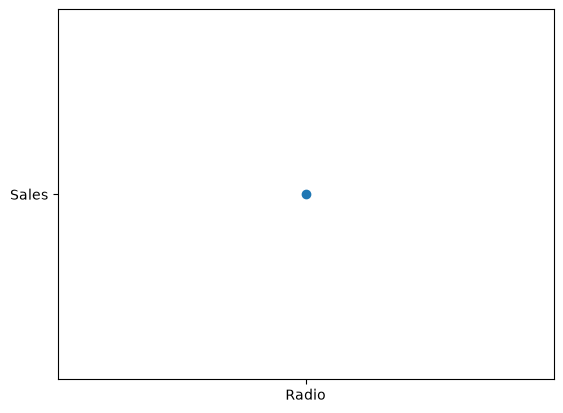

In [12]:
# sns.pairplot(df)
plt.scatter(x=['Radio'],y=['Sales'])

Train Test split


In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,:-1],df.iloc[:,-1],test_size=0.2,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape 

((400, 3), (100, 3), (400,), (100,))

Apply Linear Regrassion


In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

lr.fit(x_train,y_train) # train model
y_pread = lr.predict(x_test)

In [ ]:
y_pread # value of sales

array([14.83861917, 13.46605205,  9.801101  ,  6.18192226, 10.6865903 ,
       19.88303307, 13.53115923,  9.99125496, 21.06527382, 16.30208301,
       19.70412493, 25.51825372,  4.24477635, 13.60844777, 15.31496513,
        6.26833668,  8.82959753, 18.68695477, 14.36154772, 21.34415458,
        5.84287175, 15.5007978 , 24.0191827 , 12.70485276,  5.96539538,
       19.25070901, 15.50066468, 18.53149206,  5.85933185, 11.69278141,
       21.75490704, 18.08182611, 18.45212872, 23.35847139,  8.93898729,
       14.95642589, 13.71027636, 14.83310875,  9.33884719, 18.72760026,
       19.72046508, 15.67779743, 20.94670168, 18.03769808, 16.97499333,
       23.49939095, 12.00781136,  6.92806895,  9.05991138,  4.38074958,
       11.30957074, 10.43026668, 22.47426273,  8.81589395, 15.7672011 ,
       16.08618663, 13.28598053, 18.15112439, 14.13153108,  7.17721267,
       22.01130662, 16.56074556, 16.35725988,  8.17345855, 12.97787674,
       13.22653013, 11.41779725, 11.63883152, 24.1261442 , 17.93

Matrix R2 score

In [20]:
from sklearn.metrics import r2_score,mean_absolute_error
mean_absolute_error(y_test,y_pread)

1.3420941036062195

In [22]:
r2_score(y_test,y_test)

1.0

Predict System

In [29]:
def predict_sales(tv_budget,Radio_budget,Newspaper_budget):
    features = np.array([[tv_budget,Radio_budget,Newspaper_budget]])
    result = lr.predict(features).reshape(1,-1)
    return result

In [30]:
df.iloc[0]

TV           192.1
Radio          1.3
Newspaper     31.6
Sales         12.4
Name: 0, dtype: float64

In [31]:
tv_budget = 192.1
Radio_budget = 1.3
Newspaper_budget = 31.6
sales = predict_sales(tv_budget,Radio_budget,Newspaper_budget)

c:\Users\cheta\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [32]:
sales

array([[12.00781136]])

In [33]:
import pickle
pickle.dump(lr,open('Linear_Regression_model.pkl','wb'))